In [1]:
!pip install tensorflow matplotlib seaborn pandas scikit-learn -q

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import time

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    AveragePooling2D, Flatten,
    Dense, Dropout
)
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score, confusion_matrix

In [3]:
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2817s 17us/step
Training Data: (50000, 32, 32, 3)
Testing Data: (10000, 32, 32, 3)
Training Labels: (50000, 1)
Testing Labels: (10000, 1)


In [4]:
# Normalize images
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Convert labels into one-dimensional arrays
y_train = y_train.flatten()
y_test = y_test.flatten()

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("Minimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())

Training Shape: (50000, 32, 32, 3)
Testing Shape: (10000, 32, 32, 3)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


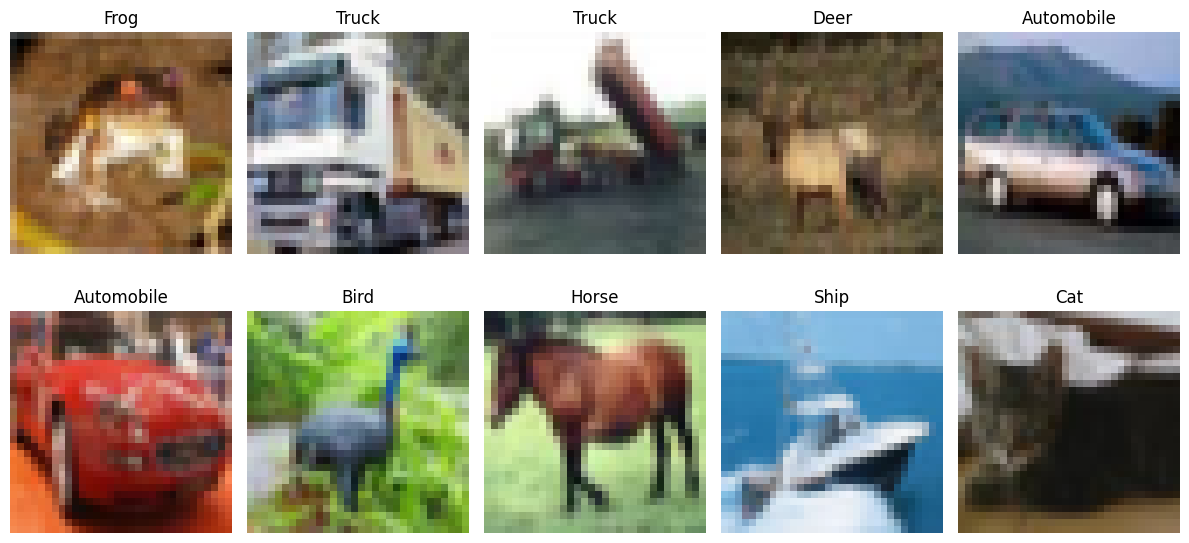

In [5]:
class_names = [
    'Airplane', 'Automobile', 'Bird',
    'Cat', 'Deer', 'Dog',
    'Frog', 'Horse', 'Ship', 'Truck'
]

plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i])

    plt.title(class_names[y_train[i]])

    plt.axis('off')

plt.tight_layout()
plt.show()

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=5000,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (45000, 32, 32, 3)
Validation: (5000, 32, 32, 3)
Testing: (10000, 32, 32, 3)


In [7]:
def build_cnn(
    kernel_size=3,
    stride=1,
    padding='same',
    pooling='max'
):

    model = Sequential()

    model.add(Input(shape=(32, 32, 3)))

    # First convolutional layer
    model.add(Conv2D(
        32,
        kernel_size=(kernel_size, kernel_size),
        strides=(stride, stride),
        padding=padding,
        activation='relu'
    ))

    # First pooling layer
    if pooling == 'max':
        model.add(MaxPooling2D(pool_size=(2, 2)))
    else:
        model.add(AveragePooling2D(pool_size=(2, 2)))

    # Second convolutional layer
    model.add(Conv2D(
        64,
        kernel_size=(3, 3),
        strides=1,
        padding='same',
        activation='relu'
    ))

    model.add(MaxPooling2D(pool_size=(2, 2)))

    # Classification layers
    model.add(Flatten())

    model.add(Dense(128, activation='relu'))

    model.add(Dropout(0.3))

    model.add(Dense(10, activation='softmax'))

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [8]:
model = build_cnn()

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
kernel_sizes = [3, 5]
strides = [1, 2]
paddings = ['same', 'valid']
poolings = ['max', 'average']

experiments = []

for kernel in kernel_sizes:
    for stride in strides:
        for padding in paddings:
            for pooling in poolings:

                experiments.append({
                    'kernel': kernel,
                    'stride': stride,
                    'padding': padding,
                    'pooling': pooling
                })

print("Total Experiments:", len(experiments))

for i, exp in enumerate(experiments, 1):
    print(i, exp)

Total Experiments: 16
1 {'kernel': 3, 'stride': 1, 'padding': 'same', 'pooling': 'max'}
2 {'kernel': 3, 'stride': 1, 'padding': 'same', 'pooling': 'average'}
3 {'kernel': 3, 'stride': 1, 'padding': 'valid', 'pooling': 'max'}
4 {'kernel': 3, 'stride': 1, 'padding': 'valid', 'pooling': 'average'}
5 {'kernel': 3, 'stride': 2, 'padding': 'same', 'pooling': 'max'}
6 {'kernel': 3, 'stride': 2, 'padding': 'same', 'pooling': 'average'}
7 {'kernel': 3, 'stride': 2, 'padding': 'valid', 'pooling': 'max'}
8 {'kernel': 3, 'stride': 2, 'padding': 'valid', 'pooling': 'average'}
9 {'kernel': 5, 'stride': 1, 'padding': 'same', 'pooling': 'max'}
10 {'kernel': 5, 'stride': 1, 'padding': 'same', 'pooling': 'average'}
11 {'kernel': 5, 'stride': 1, 'padding': 'valid', 'pooling': 'max'}
12 {'kernel': 5, 'stride': 1, 'padding': 'valid', 'pooling': 'average'}
13 {'kernel': 5, 'stride': 2, 'padding': 'same', 'pooling': 'max'}
14 {'kernel': 5, 'stride': 2, 'padding': 'same', 'pooling': 'average'}
15 {'kernel': 5

In [10]:
results = []
histories = {}
trained_models = {}

EPOCHS = 5
BATCH_SIZE = 128

for i, exp in enumerate(experiments):

    name = (
        f"K{exp['kernel']}_"
        f"S{exp['stride']}_"
        f"P{exp['padding']}_"
        f"Pool{exp['pooling']}"
    )

    print("\n" + "=" * 55)
    print(f"Experiment {i+1}/16: {name}")
    print("=" * 55)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_cnn(
        kernel_size=exp['kernel'],
        stride=exp['stride'],
        padding=exp['padding'],
        pooling=exp['pooling']
    )

    start_time = time.time()

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=1
    )

    training_time = time.time() - start_time

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    results.append({
        'Configuration': name,
        'Kernel': exp['kernel'],
        'Stride': exp['stride'],
        'Padding': exp['padding'],
        'Pooling': exp['pooling'],
        'Training Loss': history.history['loss'][-1],
        'Validation Accuracy': history.history['val_accuracy'][-1] * 100,
        'Test Accuracy': test_accuracy * 100,
        'Test Loss': test_loss,
        'Training Time': training_time
    })

    histories[name] = history
    trained_models[name] = model

    print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
    print("Training Time:", round(training_time, 2), "seconds")


Experiment 1/16: K3_S1_Psame_Poolmax
Epoch 1/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.4257 - loss: 1.5780 - val_accuracy: 0.5646 - val_loss: 1.2425
Epoch 2/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.5608 - loss: 1.2330 - val_accuracy: 0.6288 - val_loss: 1.0721
Epoch 3/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6121 - loss: 1.0996 - val_accuracy: 0.6486 - val_loss: 0.9966
Epoch 4/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6434 - loss: 1.0107 - val_accuracy: 0.6774 - val_loss: 0.9263
Epoch 5/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6710 - loss: 0.9434 - val_accuracy: 0.6836 - val_loss: 0.8948
Test Accuracy: 68.59 %
Training Time: 27.89 seconds

Experiment 2/16: K3_S1_Psame_Poolaverage
Epoch 1/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.4194 - loss: 1.6069 - val_accuracy: 0.5296 - val_loss: 1.3166
Epoch 2/5
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5496 - loss: 1.2658 - val_accuracy: 0.

In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Test Accuracy',
    ascending=False
)

print("\nFINAL EXPERIMENT RESULTS")

print(results_df.round(4).to_string(index=False))

In [ ]:
plt.figure(figsize=(14, 7))

for name, history in histories.items():

    plt.plot(
        history.history['loss'],
        label=name
    )

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    fontsize=7
)

plt.grid()
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(14, 6))

plt.bar(
    results_df['Configuration'],
    results_df['Test Accuracy']
)

plt.title("Test Accuracy for Different CNN Configurations")
plt.xlabel("CNN Configuration")
plt.ylabel("Test Accuracy (%)")

plt.xticks(rotation=90)
plt.grid(axis='y')

plt.tight_layout()
plt.show()

In [ ]:
kernel_comparison = results_df.groupby('Kernel')[
    'Test Accuracy'
].mean()

print(kernel_comparison)

kernel_comparison.plot(
    kind='bar',
    figsize=(7, 4),
    title='Effect of Kernel Size on Accuracy'
)

plt.xlabel("Kernel Size")
plt.ylabel("Average Test Accuracy (%)")
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

In [ ]:
stride_comparison = results_df.groupby('Stride')[
    'Test Accuracy'
].mean()

print(stride_comparison)

stride_comparison.plot(
    kind='bar',
    figsize=(7, 4),
    title='Effect of Stride on Accuracy'
)

plt.xlabel("Stride")
plt.ylabel("Average Test Accuracy (%)")
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

In [ ]:
stride_comparison = results_df.groupby('Stride')[
    'Test Accuracy'
].mean()

print(stride_comparison)

stride_comparison.plot(
    kind='bar',
    figsize=(7, 4),
    title='Effect of Stride on Accuracy'
)

plt.xlabel("Stride")
plt.ylabel("Average Test Accuracy (%)")
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

In [ ]:
padding_comparison = results_df.groupby('Padding')[
    'Test Accuracy'
].mean()

print(padding_comparison)

padding_comparison.plot(
    kind='bar',
    figsize=(7, 4),
    title='Effect of Padding on Accuracy'
)

plt.xlabel("Padding")
plt.ylabel("Average Test Accuracy (%)")
plt.grid(axis='y')
plt.show()

Pooling
average    62.414999
max        65.138749
Name: Test Accuracy, dtype: float64


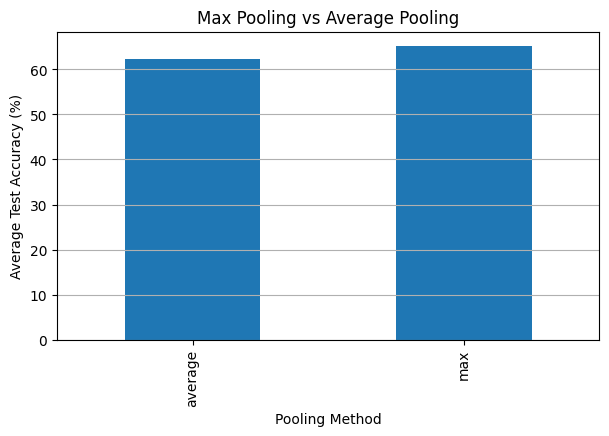

In [18]:
pooling_comparison = results_df.groupby('Pooling')[
    'Test Accuracy'
].mean()

print(pooling_comparison)

pooling_comparison.plot(
    kind='bar',
    figsize=(7, 4),
    title='Max Pooling vs Average Pooling'
)

plt.xlabel("Pooling Method")
plt.ylabel("Average Test Accuracy (%)")
plt.grid(axis='y')
plt.show()

In [19]:
best_config_name = results_df.iloc[0]['Configuration']

best_model = trained_models[best_config_name]

print("Best Configuration:", best_config_name)

# Get first convolutional layer
first_conv = next(
    layer for layer in best_model.layers
    if isinstance(layer, Conv2D)
)

filters, biases = first_conv.get_weights()

print("Filter Shape:", filters.shape)

Best Configuration: K3_S1_Psame_Poolmax
Filter Shape: (3, 3, 3, 32)


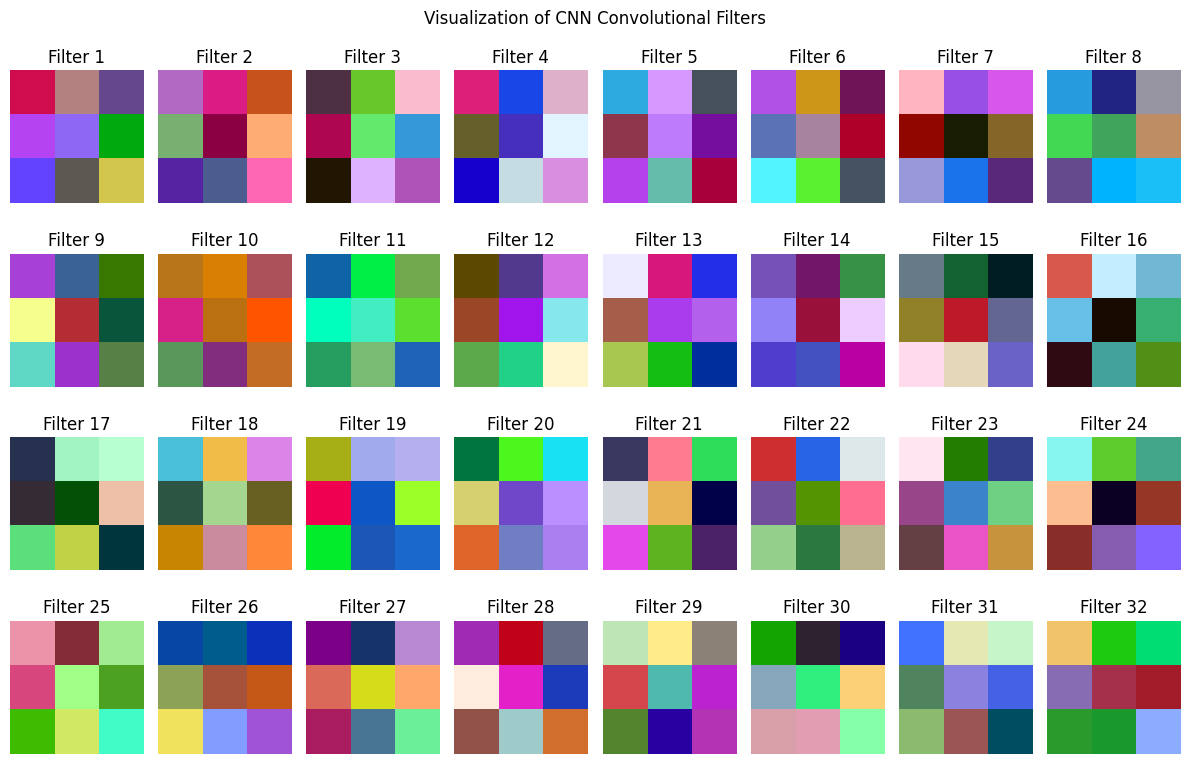

In [20]:
plt.figure(figsize=(12, 8))

for i in range(min(32, filters.shape[-1])):

    plt.subplot(4, 8, i + 1)

    filter_image = filters[:, :, :, i]

    # Normalize filter values for display
    filter_image = (
        filter_image - filter_image.min()
    ) / (
        filter_image.max() - filter_image.min() + 1e-8
    )

    plt.imshow(filter_image)

    plt.title(f"Filter {i+1}")
    plt.axis('off')

plt.suptitle("Visualization of CNN Convolutional Filters")
plt.tight_layout()
plt.show()

In [21]:
# Select one test image
sample_image = X_test[0:1]

# Create feature extraction model
feature_model = Model(
    inputs=best_model.inputs,
    outputs=[
        layer.output
        for layer in best_model.layers
        if isinstance(layer, Conv2D)
    ]
)

# Extract feature maps
feature_maps = feature_model.predict(
    sample_image,
    verbose=0
)

print("Number of convolutional layers:", len(feature_maps))

Number of convolutional layers: 2


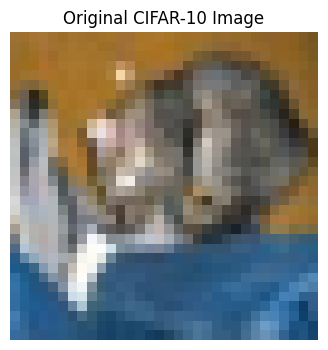

In [22]:
plt.figure(figsize=(4, 4))

plt.imshow(sample_image[0])
plt.title("Original CIFAR-10 Image")
plt.axis('off')

plt.show()

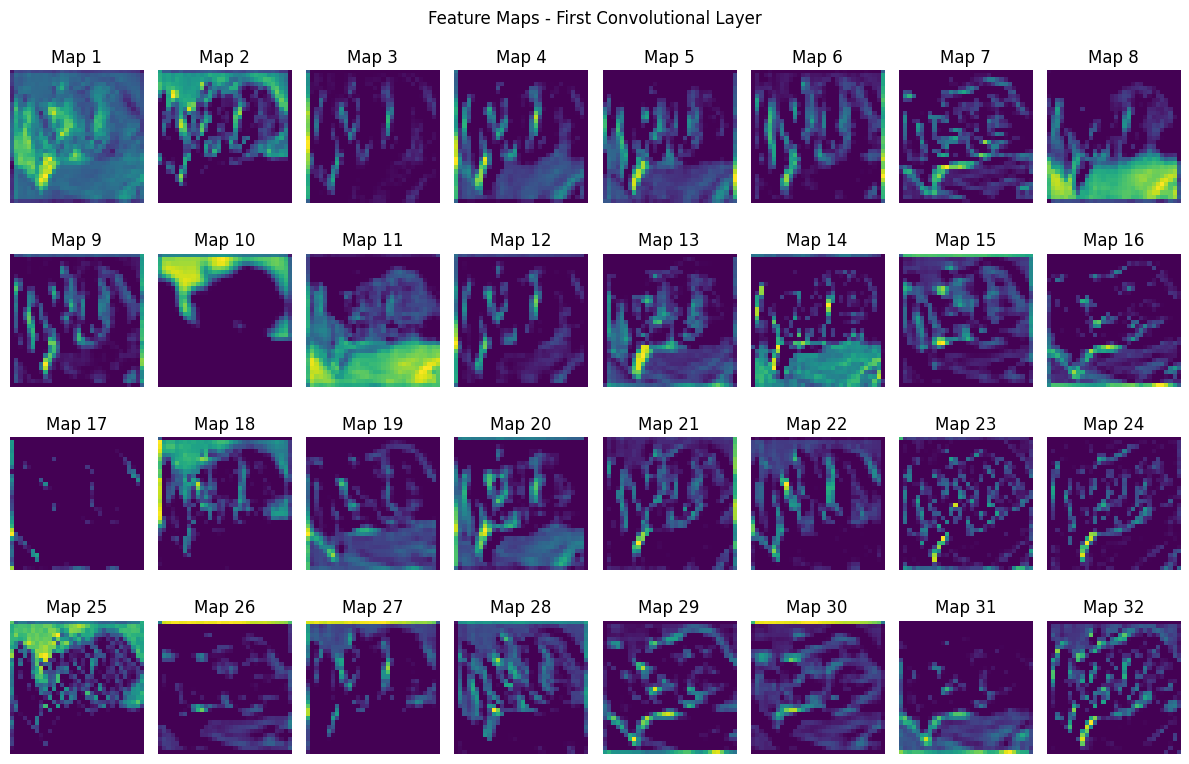

In [23]:
first_feature_map = feature_maps[0]

plt.figure(figsize=(12, 8))

for i in range(min(32, first_feature_map.shape[-1])):

    plt.subplot(4, 8, i + 1)

    plt.imshow(
        first_feature_map[0, :, :, i],
        cmap='viridis'
    )

    plt.title(f"Map {i+1}")
    plt.axis('off')

plt.suptitle("Feature Maps - First Convolutional Layer")
plt.tight_layout()
plt.show()

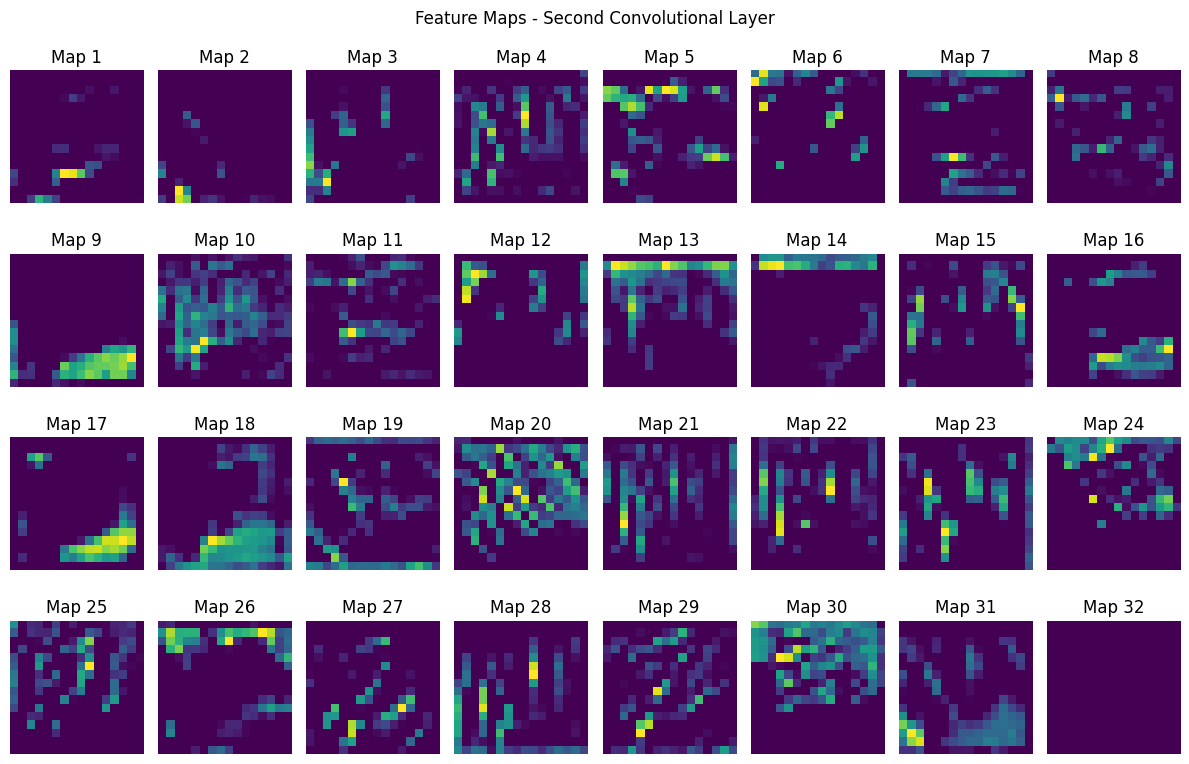

In [24]:
if len(feature_maps) > 1:

    second_feature_map = feature_maps[1]

    plt.figure(figsize=(12, 8))

    for i in range(min(32, second_feature_map.shape[-1])):

        plt.subplot(4, 8, i + 1)

        plt.imshow(
            second_feature_map[0, :, :, i],
            cmap='viridis'
        )

        plt.title(f"Map {i+1}")
        plt.axis('off')

    plt.suptitle("Feature Maps - Second Convolutional Layer")
    plt.tight_layout()
    plt.show()

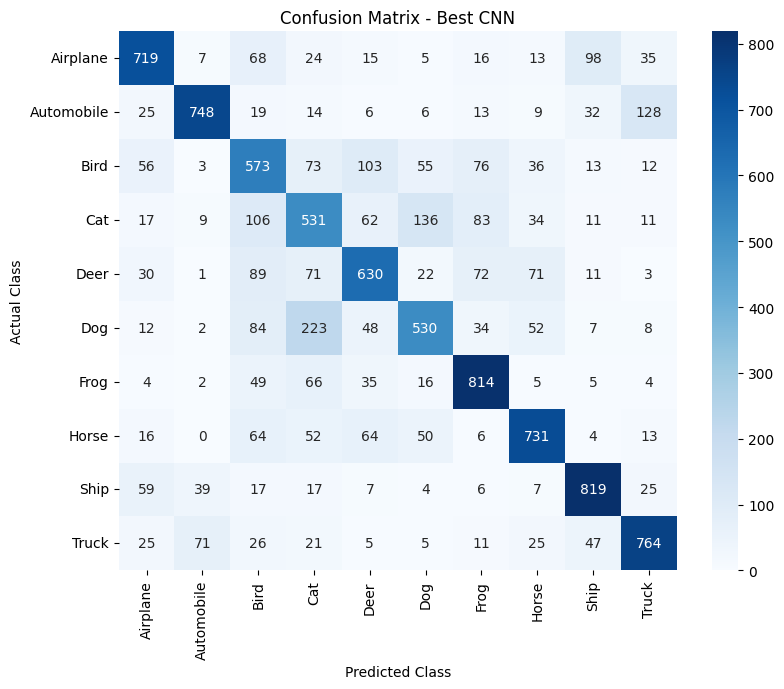

In [25]:
predictions = best_model.predict(X_test, verbose=0)

y_pred = np.argmax(predictions, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Best CNN")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [26]:
best_result = results_df.iloc[0]

print("\nBEST CNN CONFIGURATION")
print("-" * 40)

print("Configuration:", best_result['Configuration'])
print("Kernel Size:", best_result['Kernel'])
print("Stride:", best_result['Stride'])
print("Padding:", best_result['Padding'])
print("Pooling:", best_result['Pooling'])

print("Test Accuracy:",
      round(best_result['Test Accuracy'], 2), "%")

print("Training Loss:",
      round(best_result['Training Loss'], 4))

print("Training Time:",
      round(best_result['Training Time'], 2), "seconds")


BEST CNN CONFIGURATION
----------------------------------------
Configuration: K3_S1_Psame_Poolmax
Kernel Size: 3
Stride: 1
Padding: same
Pooling: max
Test Accuracy: 68.59 %
Training Loss: 0.9434
Training Time: 27.89 seconds
